# Global Superstore Data

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
%matplotlib inline

In [14]:
df=pd.read_csv("C:/Users/yekta/OneDrive/Desktop/Datasets/Global_Superstore.csv")

In [76]:
#df.head()

In [17]:
df.shape[1]

24

In [18]:
df.shape[0]

1000

In [19]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,1000.000000,194.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,25079.328000,53966.170103,1710.971470,5.55800,0.092840,288.920440,272.384897
std,12897.726632,33734.306466,1259.239238,2.71846,0.148666,574.504782,176.160716
min,58.000000,2920.000000,1.910000,1.00000,0.000000,-3059.820000,1.070000
25%,15118.750000,19134.000000,826.907500,4.00000,0.000000,10.037500,209.827500
50%,25084.500000,60564.000000,1585.115000,5.00000,0.000000,190.685000,258.897500
75%,34524.000000,88187.500000,2477.812500,7.00000,0.150000,518.872500,351.070250
max,51284.000000,98198.000000,9892.740000,14.00000,0.800000,4946.370000,923.630000


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          1000 non-null   int64  
 1   Order ID        1000 non-null   object 
 2   Order Date      1000 non-null   object 
 3   Ship Date       1000 non-null   object 
 4   Ship Mode       1000 non-null   object 
 5   Customer ID     1000 non-null   object 
 6   Customer Name   1000 non-null   object 
 7   Segment         1000 non-null   object 
 8   Postal Code     194 non-null    float64
 9   City            1000 non-null   object 
 10  State           1000 non-null   object 
 11  Country         1000 non-null   object 
 12  Region          1000 non-null   object 
 13  Market          1000 non-null   object 
 14  Product ID      1000 non-null   object 
 15  Category        1000 non-null   object 
 16  Sub-Category    1000 non-null   object 
 17  Product Name    1000 non-null   ob

### Check for missing values

In [23]:
df.isnull().sum()

Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Postal Code       806
City                0
State               0
Country             0
Region              0
Market              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Shipping Cost       0
Order Priority      0
dtype: int64

### Handle any missing or inconsistent data

In [25]:
df.dropna(inplace=True)

### Convert data types


In [29]:
df["Order Date"]=pd.to_datetime(df["Order Date"])
df["Ship Date"]=pd.to_datetime(df["Ship Date"])

### Calculate total sales and profit

In [35]:
Total_sales=df["Sales"].sum()
print(f"Total sales: {Total_sales}")

Total sales: 54535.08


In [36]:
Total_profit=df["Profit"].sum()
print(f"Total Profti: {Total_profit}")

Total Profti: 12063.97


### Identify top-selling products

In [41]:
Top_selling_product=df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(Top_selling_product)

Product Name
GBC Ibimaster 500 Manual ProClick Binding System           9892.74
GBC DocuBind P400 Electric Binding System                  4355.17
Canon Image Class D660 Copier                              2999.95
GBC DocuBind 300 Electric Binding Machine                  2419.51
Hon 5100 Series Wood Tables                                2036.86
Bady BDG101FRU Card Printer                                1439.98
Avaya IP Phone 1140E VoIP phone                            1394.95
Global Adaptabilites Bookcase, Cherry/Storm Gray Finish    1292.94
Tennsco Single-Tier Lockers                                1126.02
Ibico Ibimaster 300 Manual Binding System                  1103.97
Name: Sales, dtype: float64


### Analyze sales by region

In [43]:
Sales_by_region= df.groupby("Region")["Sales"].sum()
print(Sales_by_region)

Region
Central US     17187.94
Eastern US     12256.44
Southern US     8360.75
Western US     16729.95
Name: Sales, dtype: float64


### Examine the relationship between sales and profit

In [46]:
correlation= df["Sales"].corr(df["Profit"])
print(f"Correlation between sales and profit: {correlation}")

Correlation between sales and profit: 0.9313979948257132


## Data Visualization

### Create a bar chart of sales by product category

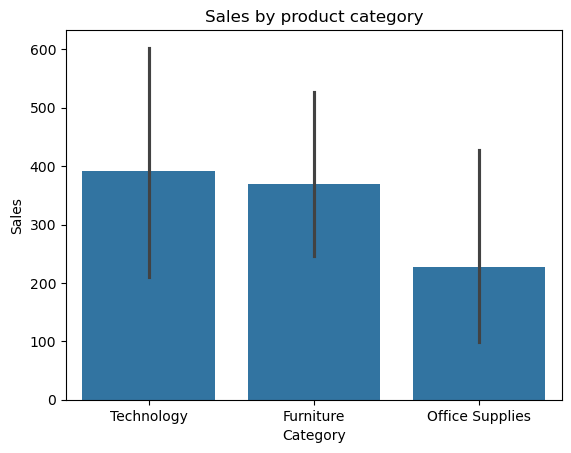

In [47]:
sns.barplot(x="Category", y="Sales", data=df)
plt.title("Sales by product category")
plt.show()

## Plot a line graph of monthly sales over time

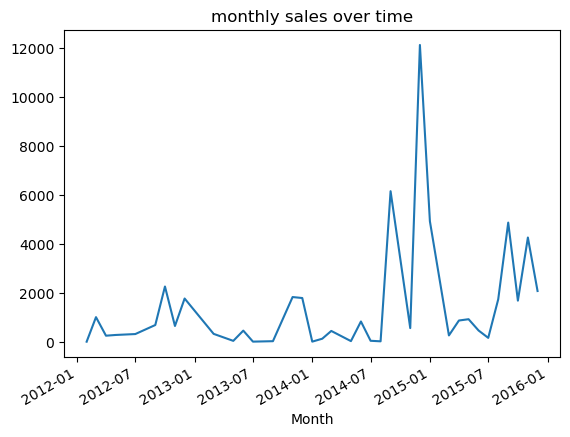

In [57]:
df["Month"]=df["Order Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales.index=monthly_sales.index.to_timestamp()
monthly_sales.plot(kind="line")
plt.title("monthly sales over time")
plt.show()

## Generate a scatter plot of sales vs. profit

<function matplotlib.pyplot.show(close=None, block=None)>

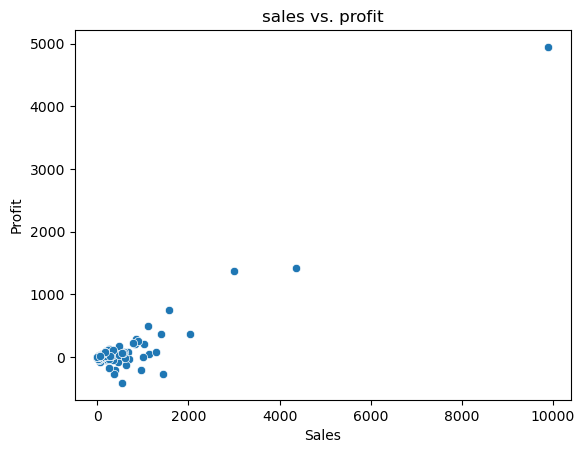

In [58]:
sns.scatterplot(x="Sales", y="Profit", data=df)
plt.title("sales vs. profit")
plt.show

###  Produce a heatmap of sales by region and product category

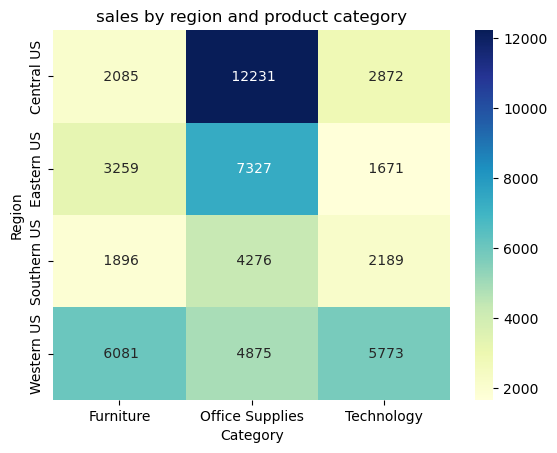

In [61]:
pivot_table=df.pivot_table(values="Sales", index="Region", columns="Category", aggfunc="sum")
sns.heatmap(pivot_table, annot= True, fmt=" .0f", cmap="YlGnBu")
plt.title("sales by region and product category")
plt.show()

### insights about GlobalMart's sales performance


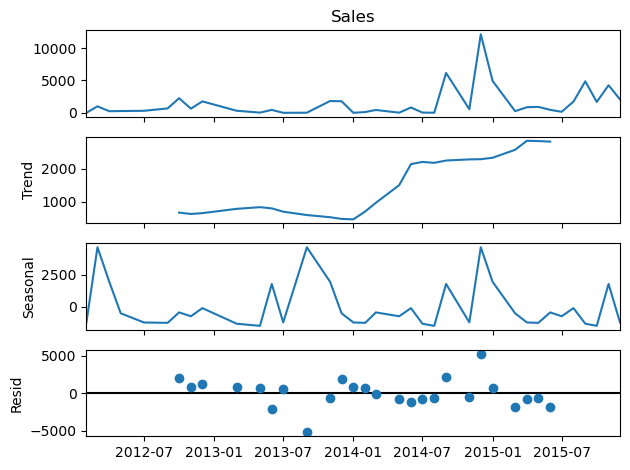

In [70]:
result= seasonal_decompose(monthly_sales, model="additive", period=12)
result.plot()
plt.show()

In [72]:
total_discount=df["Discount"].sum()
print(f"Total Discount: {total_discount}")

Total Discount: 29.95


In [73]:
total_profit=df["Profit"].sum()
print(f"Total profit: {total_profit}")

Total profit: 12063.97


### Correlation between discount and profit

In [75]:
discount_profit_correlation= df[["Discount", "Profit"]].corr().iloc[0,1]
print(f"discount_profit_correlation: {discount_profit_correlation}")

discount_profit_correlation: -0.16262271039478665
